# Calibration and Reliability of Classifier Confidence

**Module 06 · AI Safety (ISO/PAS 8800)** · Notebook 4 of 7

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/06_AI_Safety_ISO_PAS_8800/04_calibration.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [02 Uncertainty types](02_uncertainty_types.ipynb), [03 MC dropout and ensembles](03_mc_dropout_and_deep_ensembles.ipynb) | ISO/PAS 8800:2024, ISO 21448:2022 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

- Define calibration precisely (top-label confidence vs observed accuracy).
- Measure it with a **reliability diagram**, **expected calibration error (ECE)** and the proper scoring rules **NLL** and **Brier score**, each with a **bootstrap confidence interval**.
- Fit **temperature scaling** correctly (minimise validation NLL over $T>0$), plus Platt scaling and isotonic regression, using a strict train / validation / test protocol.
- Explain what calibration does and does not change (accuracy, ranking, thresholded decisions).
- Use calibrated probabilities for **expected-cost decisions** and see how calibration degrades under **distribution shift**.

## Introduction

A model predicts "pedestrian" with confidence 0.9. What does that mean?
- **Calibrated:** among all predictions made with confidence 0.9, about 90 % are correct.
- **Miscalibrated:** the true rate may be 60 % or 99 %.

Guo et al. (2017) showed that modern neural networks are often **overconfident**: high accuracy, but confidences above the observed accuracy. Overfitting the negative log-likelihood is one mechanism.

**Why calibration matters for AVs:**
- Downstream components (tracking, sensor fusion, planning) combine probabilities and need them to mean what they say.
- Expected-cost decisions ("brake if the expected cost of not braking exceeds that of braking") are only correct with calibrated probabilities.
- ISO 21448 and ISO/PAS 8800 require the limitations of the perception function to be understood; a confidence score is only useful as evidence if its calibration has been measured on representative data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import optimize
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression

rng = np.random.default_rng(42)
torch.manual_seed(42)
torch.set_num_threads(1)              # tiny model: one thread is fastest and reproducible
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
OI = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]
pd.set_option("display.width", 160)

## 1. Definitions and metrics

**Perfect (top-label) calibration:** $P(\hat Y = Y \mid \hat P = p) = p$ for all $p$, where $\hat Y$ is the predicted class and $\hat P$ its confidence (the maximum class probability).

**Reliability diagram:** bin the predictions by confidence, then plot the mean confidence of each bin (x) against its accuracy (y). The diagonal is perfect calibration; points *below* it are **overconfident**, points *above* it **underconfident**. For two classes the top-label confidence lies in $[0.5, 1]$, so the bins below 0.5 stay empty.

**Expected calibration error** (equal-width bins $B_1,\dots,B_K$ over the confidence):
$$\mathrm{ECE} = \sum_{k=1}^{K} \frac{|B_k|}{n}\,\big|\mathrm{acc}(B_k) - \mathrm{conf}(B_k)\big| .$$
ECE = 0.10 means that the bin-weighted average gap between accuracy and confidence is 10 percentage points. ECE depends on the number and type of bins, is biased upwards for small samples and has high variance, so it should be reported with a confidence interval (Nixon et al., 2019; Kumar et al., 2019). It can also be small for a useless model that always predicts the base rate.

**Proper scoring rules** complement ECE because they reward both calibration and sharpness:
- Negative log-likelihood $\mathrm{NLL} = -\frac1n\sum_i \log \hat p_{i,y_i}$;
- Brier score $= \frac1n\sum_i\sum_c (\hat p_{i,c} - \mathbb 1[y_i=c])^2$ (multi-class form; for two classes it is twice the common binary form $\frac1n\sum_i(\hat p_i - y_i)^2$).

The functions below work on probability matrices of shape (n, classes) and give the same results as `avsafety.uq` in this repository (see repo `avsafety/`).

In [2]:
def softmax(logits, temperature=1.0):
    z = np.asarray(logits, dtype=np.float64) / temperature
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def reliability_bins(probs, labels, n_bins=15):
    """Per bin: (mean confidence, accuracy, count); top-label confidence, equal-width bins on [0, 1]."""
    conf = probs.max(axis=1)
    correct = (probs.argmax(axis=1) == labels).astype(float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    idx = np.clip(np.digitize(conf, edges[1:-1], right=True), 0, n_bins - 1)
    return [(conf[idx == b].mean() if (idx == b).any() else np.nan,
             correct[idx == b].mean() if (idx == b).any() else np.nan, int((idx == b).sum())) for b in range(n_bins)]

def expected_calibration_error(probs, labels, n_bins=15):
    n = len(labels)
    return float(sum(c / n * abs(a - m) for m, a, c in reliability_bins(probs, labels, n_bins) if c))

def negative_log_likelihood(probs, labels, eps=1e-12):
    return float(-np.mean(np.log(np.clip(probs[np.arange(len(labels)), labels], eps, 1.0))))

def brier_score(probs, labels):
    onehot = np.eye(probs.shape[1])[labels]
    return float(np.mean(np.sum((probs - onehot) ** 2, axis=1)))

def to_two_class(p_pos):
    """Binary P(y=1) -> (n, 2) probability matrix."""
    p_pos = np.asarray(p_pos, dtype=np.float64)
    return np.stack([1 - p_pos, p_pos], axis=1)

# Sanity check on a synthetic, perfectly calibrated source: ECE should be small, and shrink with n
for n in (500, 50_000):
    p = rng.uniform(0.5, 1.0, n)                       # confidences of the predicted class (class 1)
    y = (rng.random(n) < p).astype(int)                # correct with exactly that probability
    print(f"perfectly calibrated source, n = {n:6d}: ECE = {expected_calibration_error(to_two_class(p), y):.4f}")

perfectly calibrated source, n =    500: ECE = 0.0401
perfectly calibrated source, n =  50000: ECE = 0.0040


In [3]:
def reliability_diagram(probs, labels, title, n_bins=15, ax=None, ax_hist=None):
    stats = reliability_bins(probs, labels, n_bins)
    width = 1.0 / n_bins
    centres = (np.arange(n_bins) + 0.5) * width
    ece = expected_calibration_error(probs, labels, n_bins)
    ax.plot([0, 1], [0, 1], "k--", lw=1.5, label="Perfect calibration")
    for k, (m, acc, cnt) in enumerate(stats):
        if not cnt:
            continue
        ax.bar(centres[k], acc, width=width * 0.95, color=OI[4], edgecolor="black", alpha=0.8,
               label="Accuracy in bin" if k == np.nanargmax([s[2] for s in stats]) else None)
        gap_lo, gap_hi = sorted([acc, m])
        ax.bar(centres[k], gap_hi - gap_lo, bottom=gap_lo, width=width * 0.95,
               color=OI[5] if m > acc else OI[2], alpha=0.45, edgecolor="black", hatch="//" if m > acc else "..")
    ax.bar([np.nan], [np.nan], color=OI[5], alpha=0.45, hatch="//", label="Gap: overconfident (conf > acc)")
    ax.bar([np.nan], [np.nan], color=OI[2], alpha=0.45, hatch="..", label="Gap: underconfident (conf < acc)")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Top-label confidence (mean in bin)"); ax.set_ylabel("Accuracy in bin (fraction correct)")
    ax.set_title(f"{title}\nECE = {ece:.3f} ({n_bins} bins)", fontweight="bold"); ax.legend(fontsize=8, loc="upper left")
    if ax_hist is not None:
        ax_hist.bar(centres, [s[2] for s in stats], width=width * 0.95, color=OI[1], edgecolor="black")
        ax_hist.set_xlim(0, 1); ax_hist.set_xlabel("Top-label confidence"); ax_hist.set_ylabel("Number of predictions")
        ax_hist.set_title("Confidence histogram")
    return ece

## 2. A model that becomes overconfident

Synthetic binary task with 5 % label noise (`flip_y`). Data are split **once** into training (50 %), **validation** (25 %, used only to fit calibrators) and **test** (25 %, used only for reporting). The network is trained long enough to overfit the NLL on the training set, the mechanism behind overconfidence described by Guo et al. (2017).

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

Train 2000, validation 1000, test 1000


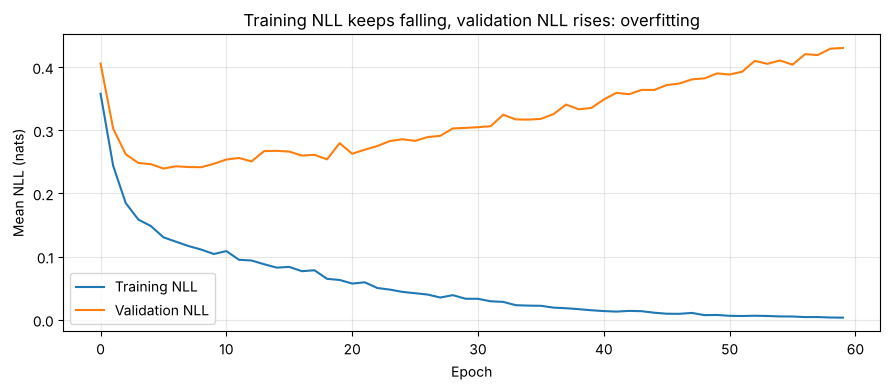

Validation NLL minimum at epoch 6 (0.239); final 0.430


In [4]:
X, y = make_classification(n_samples=4000, n_features=20, n_informative=10, n_redundant=5,
                           flip_y=0.05, class_sep=1.0, random_state=42)
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.5, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42, stratify=y_tmp)
print(f"Train {len(X_train)}, validation {len(X_val)}, test {len(X_test)}")

class BinaryClassifier(nn.Module):
    def __init__(self, d=20, h=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)                   # logit of P(y = 1)

tt = lambda a: torch.as_tensor(a, dtype=torch.float32)
model = BinaryClassifier()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)      # no weight decay, no early stopping: overfits NLL
g = torch.Generator().manual_seed(0)
hist = {"train": [], "val": []}
Xtr_t, ytr_t, Xv_t, yv_t = tt(X_train), tt(y_train), tt(X_val), tt(y_val)
for epoch in range(60):
    model.train()
    perm = torch.randperm(len(Xtr_t), generator=g)
    for i in range(0, len(perm), 64):
        idx = perm[i:i + 64]
        opt.zero_grad(); loss = F.binary_cross_entropy_with_logits(model(Xtr_t[idx]), ytr_t[idx]); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        hist["train"].append(F.binary_cross_entropy_with_logits(model(Xtr_t), ytr_t).item())
        hist["val"].append(F.binary_cross_entropy_with_logits(model(Xv_t), yv_t).item())

with torch.no_grad():
    z_val = model(Xv_t).double().numpy()
    z_test = model(tt(X_test)).double().numpy()
logits2 = lambda z: np.stack([np.zeros_like(z), z], axis=1)     # binary logit -> 2-class logits [0, z]

plt.figure(figsize=(9, 4))
plt.plot(hist["train"], label="Training NLL"); plt.plot(hist["val"], label="Validation NLL")
plt.xlabel("Epoch"); plt.ylabel("Mean NLL (nats)"); plt.title("Training NLL keeps falling, validation NLL rises: overfitting")
plt.legend(); plt.tight_layout(); plt.show()
best = int(np.argmin(hist["val"]))
print(f"Validation NLL minimum at epoch {best + 1} ({hist['val'][best]:.3f}); final {hist['val'][-1]:.3f}")

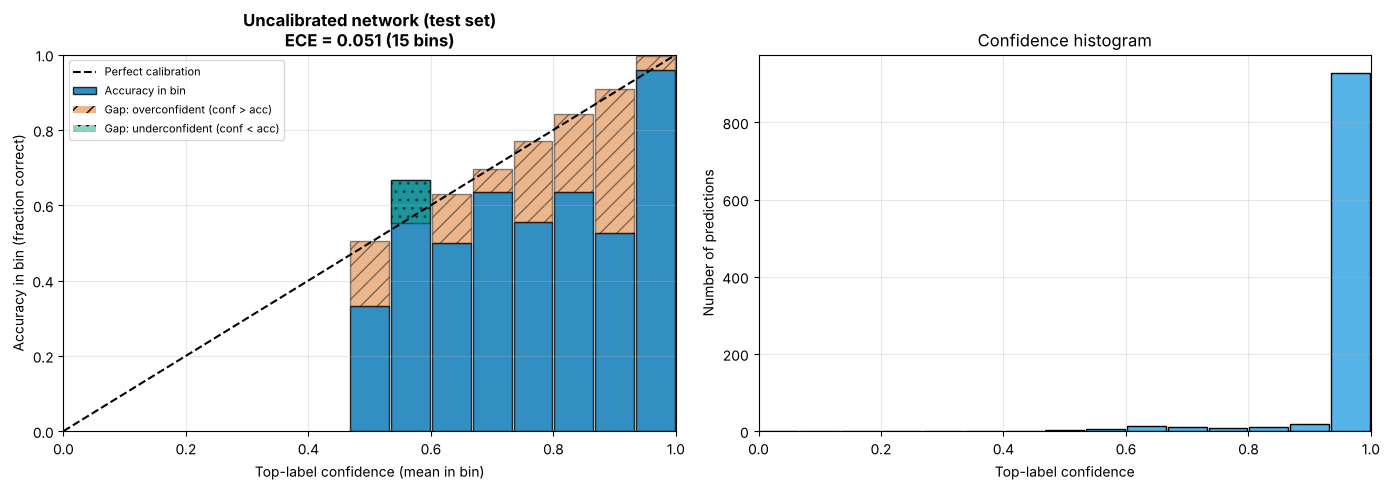

Test accuracy 0.930, mean confidence 0.980 -> overconfident by 0.050
ECE 0.0510, NLL 0.3977, Brier 0.1182


In [5]:
probs_raw = softmax(logits2(z_test))
acc_raw = np.mean(probs_raw.argmax(1) == y_test)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ece_raw = reliability_diagram(probs_raw, y_test, "Uncalibrated network (test set)", ax=ax1, ax_hist=ax2)
plt.tight_layout(); plt.show()
mean_conf = probs_raw.max(1).mean()
print(f"Test accuracy {acc_raw:.3f}, mean confidence {mean_conf:.3f} -> "
      f"{'overconfident' if mean_conf > acc_raw else 'underconfident'} by {abs(mean_conf - acc_raw):.3f}")
print(f"ECE {ece_raw:.4f}, NLL {negative_log_likelihood(probs_raw, y_test):.4f}, Brier {brier_score(probs_raw, y_test):.4f}")

## 3. Post-hoc calibration methods

All calibrators are **fitted on the validation set** and **evaluated on the test set**.

### 3.1 Temperature scaling (Guo et al., 2017)

Divide the logits by a single scalar $T>0$: $\hat p = \mathrm{softmax}(z/T)$.
- $T>1$ softens the probabilities (corrects overconfidence), $T<1$ sharpens them (corrects underconfidence).
- $T$ is fitted by **minimising the validation NLL**. ECE is not used as the objective: it is binned, non-smooth and biased.
- Optimise over $\log T$, so that $T$ stays positive, and in float64. (A common bug is to optimise a float32 loss with finite-difference gradients: the step of $10^{-8}$ in $T$ does not change the float32 loss, the gradient is zero and the optimiser stops at $T=1$.)
- The argmax, and therefore accuracy at the 0.5 threshold, is unchanged; decisions at any other threshold do change.
- A strong in-distribution baseline; its calibration degrades under distribution shift (Ovadia et al., 2019).

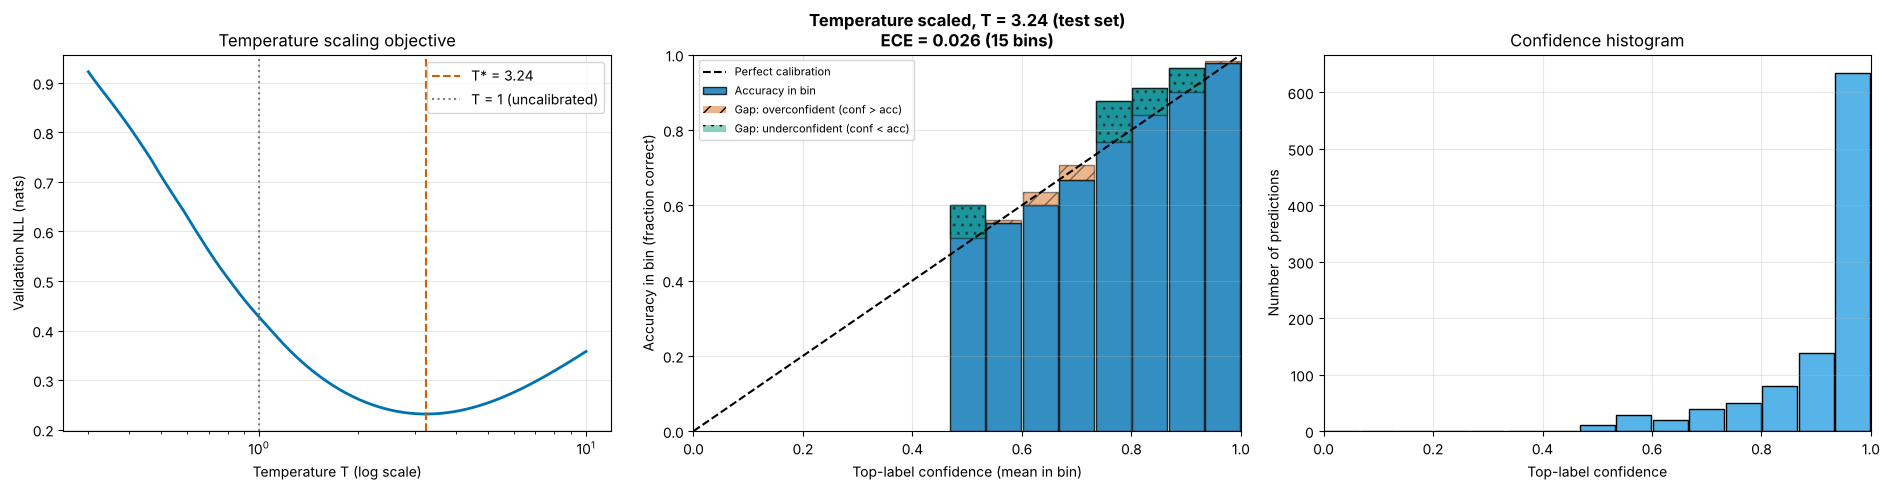

Fitted T = 3.240 (model was overconfident).
Accuracy unchanged: 0.930 vs 0.930
Test ECE 0.0510 -> 0.0255; NLL 0.3977 -> 0.2171


In [6]:
def fit_temperature(val_logits, val_labels):
    """T > 0 minimising validation NLL, optimised over log T in float64 (same as avsafety.uq.fit_temperature)."""
    nll = lambda log_t: negative_log_likelihood(softmax(val_logits, np.exp(log_t)), val_labels)
    res = optimize.minimize_scalar(nll, bounds=(-3.0, 3.0), method="bounded")
    return float(np.exp(res.x))

T_opt = fit_temperature(logits2(z_val), y_val)
probs_ts = softmax(logits2(z_test), T_opt)

Ts = np.exp(np.linspace(np.log(0.3), np.log(10), 80))
val_nll = [negative_log_likelihood(softmax(logits2(z_val), T), y_val) for T in Ts]
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(19, 5))
ax0.plot(Ts, val_nll, color=OI[4], lw=2)
ax0.axvline(T_opt, color=OI[5], ls="--", label=f"T* = {T_opt:.2f}")
ax0.axvline(1.0, color="grey", ls=":", label="T = 1 (uncalibrated)")
ax0.set_xscale("log"); ax0.set_xlabel("Temperature T (log scale)"); ax0.set_ylabel("Validation NLL (nats)")
ax0.set_title("Temperature scaling objective"); ax0.legend()
ece_ts = reliability_diagram(probs_ts, y_test, f"Temperature scaled, T = {T_opt:.2f} (test set)", ax=ax1, ax_hist=ax2)
plt.tight_layout(); plt.show()
print(f"Fitted T = {T_opt:.3f} ({'model was overconfident' if T_opt > 1 else 'model was underconfident'}).")
print(f"Accuracy unchanged: {np.mean(probs_ts.argmax(1) == y_test):.3f} vs {acc_raw:.3f}")
print(f"Test ECE {ece_raw:.4f} -> {ece_ts:.4f}; NLL {negative_log_likelihood(probs_raw, y_test):.4f} -> "
      f"{negative_log_likelihood(probs_ts, y_test):.4f}")

### 3.2 Platt scaling

Fit $\hat p = \sigma(a z + b)$ on the validation logits by unregularised maximum likelihood. Temperature scaling is the special case $a = 1/T,\ b = 0$. The extra bias $b$ shifts the 0.5 decision boundary, so **accuracy can change**. (Platt's original 1999 method also used smoothed targets; plain maximum likelihood is shown here. scikit-learn's `LogisticRegression` applies L2 regularisation by default, which shrinks $a$; we therefore fit directly.)

### 3.3 Isotonic regression

A non-parametric, monotone, piecewise-constant map from score to probability (Zadrozny & Elkan, 2002). Very flexible, but it needs more validation data, can overfit, and maps ranges of scores to ties, which can change accuracy and ranking (AUROC).

Platt: a = 0.311 (equivalent T = 3.22), b = -0.134
Isotonic: 32 breakpoints; distinct output values on test: 22


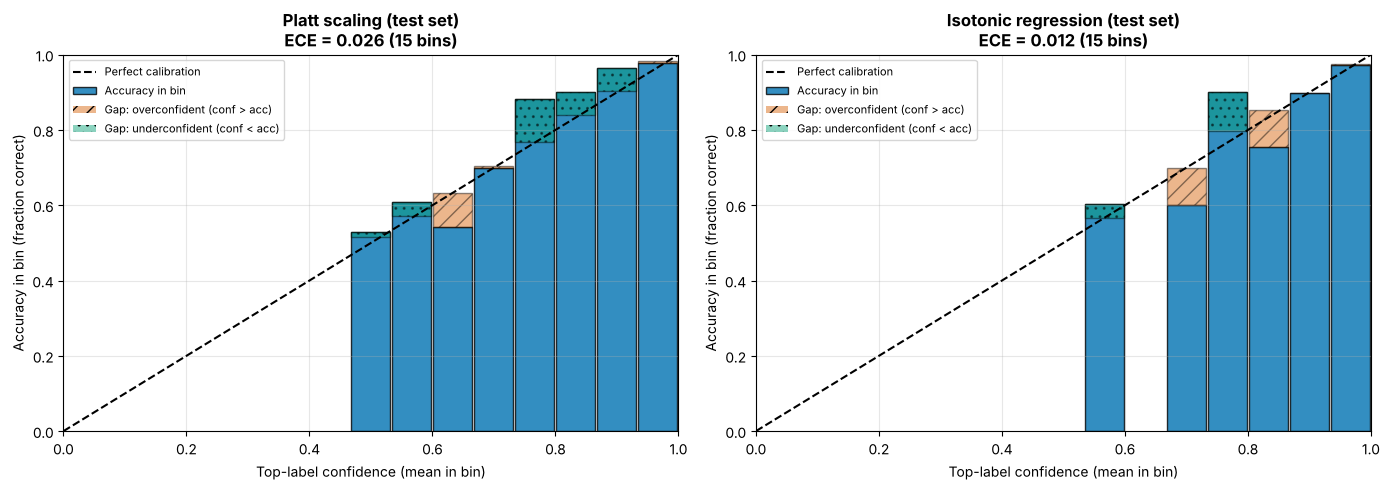

In [7]:
def fit_platt(z, y):
    def nll(params):
        a, b = params
        s = a * z + b
        return np.mean(np.logaddexp(0, s) - y * s)          # stable binary NLL
    res = optimize.minimize(nll, x0=[1.0, 0.0], method="BFGS")
    return res.x

a_pl, b_pl = fit_platt(z_val, y_val)
probs_platt = to_two_class(1 / (1 + np.exp(-(a_pl * z_test + b_pl))))

iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(1 / (1 + np.exp(-z_val)), y_val)
probs_iso = to_two_class(iso.predict(1 / (1 + np.exp(-z_test))))

print(f"Platt: a = {a_pl:.3f} (equivalent T = {1 / a_pl:.2f}), b = {b_pl:.3f}")
print(f"Isotonic: {len(iso.X_thresholds_)} breakpoints; distinct output values on test: {len(np.unique(probs_iso[:, 1]))}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
reliability_diagram(probs_platt, y_test, "Platt scaling (test set)", ax=axes[0])
reliability_diagram(probs_iso, y_test, "Isotonic regression (test set)", ax=axes[1])
plt.tight_layout(); plt.show()

## 4. Comparison with bootstrap confidence intervals

The test set has 1,000 samples. To see whether differences are larger than the sampling noise, we compute **95 % percentile bootstrap intervals** (2,000 resamples of the test set) and, for the comparison with the uncalibrated model, a **paired** bootstrap of the difference.

In [8]:
methods = {"Uncalibrated": probs_raw, "Temperature scaling": probs_ts,
           "Platt scaling": probs_platt, "Isotonic regression": probs_iso}
metrics = {"ECE": expected_calibration_error, "NLL": negative_log_likelihood, "Brier": brier_score,
           "Accuracy": lambda p, y: float(np.mean(p.argmax(1) == y))}

B = 2000
boot_idx = rng.integers(0, len(y_test), size=(B, len(y_test)))
boot = {m: {k: np.array([f(P[i], y_test[i]) for i in boot_idx]) for k, f in metrics.items()} for m, P in methods.items()}

rows = []
for m, P in methods.items():
    row = {"method": m}
    for k, f in metrics.items():
        lo, hi = np.percentile(boot[m][k], [2.5, 97.5])
        row[k] = f"{f(P, y_test):.4f} [{lo:.4f}, {hi:.4f}]"
    if m != "Uncalibrated":
        for k in ("ECE", "NLL"):
            d = boot[m][k] - boot["Uncalibrated"][k]
            lo, hi = np.percentile(d, [2.5, 97.5])
            row[f"Δ{k} vs uncal. (95 % CI)"] = f"{d.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]" + (" *" if hi < 0 or lo > 0 else "")
    rows.append(row)
table = pd.DataFrame(rows).set_index("method").fillna("")
print("Test-set metrics, point estimate [95 % bootstrap CI]; * = paired CI of the difference excludes 0")
print(table.to_string())

Test-set metrics, point estimate [95 % bootstrap CI]; * = paired CI of the difference excludes 0
                                         ECE                      NLL                    Brier                 Accuracy      ΔECE vs uncal. (95 % CI)      ΔNLL vs uncal. (95 % CI)
method                                                                                                                                                                             
Uncalibrated         0.0510 [0.0396, 0.0676]  0.3977 [0.2786, 0.5307]  0.1182 [0.0930, 0.1443]  0.9300 [0.9140, 0.9460]                                                            
Temperature scaling  0.0255 [0.0204, 0.0427]  0.2171 [0.1766, 0.2622]  0.1095 [0.0904, 0.1294]  0.9300 [0.9140, 0.9460]  -0.0217 [-0.0406, -0.0037] *  -0.1805 [-0.2724, -0.1020] *
Platt scaling        0.0262 [0.0209, 0.0434]  0.2164 [0.1769, 0.2617]  0.1095 [0.0906, 0.1295]  0.9300 [0.9140, 0.9450]  -0.0208 [-0.0405, -0.0016] *  -0.1812 [-0.2733, -0.1017] *
Iso

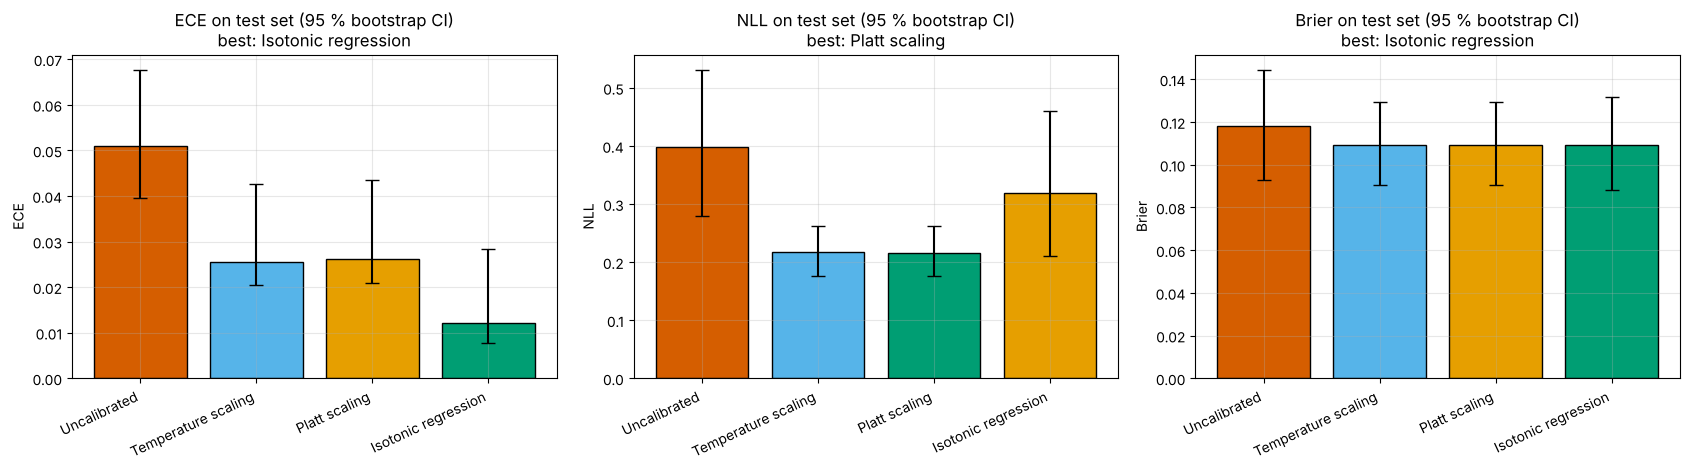

Ranking by test NLL (proper scoring rule): Platt scaling < Temperature scaling < Isotonic regression < Uncalibrated
Ranking by test ECE:                         Isotonic regression < Temperature scaling < Platt scaling < Uncalibrated
The two rankings disagree on the best method, a reminder that ECE alone is not a sufficient criterion.


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
names = list(methods)
for ax, k in zip(axes, ["ECE", "NLL", "Brier"]):
    est = np.array([metrics[k](methods[m], y_test) for m in names])
    ci = np.array([np.percentile(boot[m][k], [2.5, 97.5]) for m in names])
    order = np.argsort(est)                                       # colour by rank, best = darkest
    colours = [None] * len(names)
    for rank, i in enumerate(order):
        colours[i] = [OI[2], OI[1], OI[0], OI[5]][rank]
    ax.bar(range(len(names)), est, yerr=[est - ci[:, 0], ci[:, 1] - est], capsize=5, color=colours, edgecolor="black")
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=25, ha="right")
    ax.set_ylabel(k); ax.set_title(f"{k} on test set (95 % bootstrap CI)\nbest: {names[order[0]]}")
plt.tight_layout(); plt.show()

ranking = sorted(names, key=lambda m: metrics["NLL"](methods[m], y_test))
print("Ranking by test NLL (proper scoring rule):", " < ".join(ranking))
ranking_ece = sorted(names, key=lambda m: metrics["ECE"](methods[m], y_test))
print("Ranking by test ECE:                        ", " < ".join(ranking_ece))
if ranking[0] != ranking_ece[0]:
    print("The two rankings disagree on the best method, a reminder that ECE alone is not a sufficient criterion.")

## 5. Calibration and safety decisions

### 5.1 Thresholds vs expected cost
Two different uses of a score must not be confused:

1. **A threshold meeting a target miss rate** (false-negative rate, FNR) is chosen on validation data, e.g. from the ROC curve or with conformal risk control ([05](05_conformal_prediction.ipynb)). This does not need calibrated probabilities, because any monotone score works.
2. **Expected-cost decisions** do need calibration. If missing a pedestrian costs $C_{FN}$ and an unnecessary emergency brake costs $C_{FP}$ (rear-end risk, loss of trust), braking is optimal when
$$P(\text{ped})\,C_{FN} > \big(1 - P(\text{ped})\big)\,C_{FP} \iff P(\text{ped}) > t^* = \frac{C_{FP}}{C_{FP} + C_{FN}} .$$
This rule is only optimal if $P(\text{ped})$ is calibrated.

The costs below are **illustrative** (a missed pedestrian weighted 20 times an unnecessary brake), and class 1 plays the role of "pedestrian".

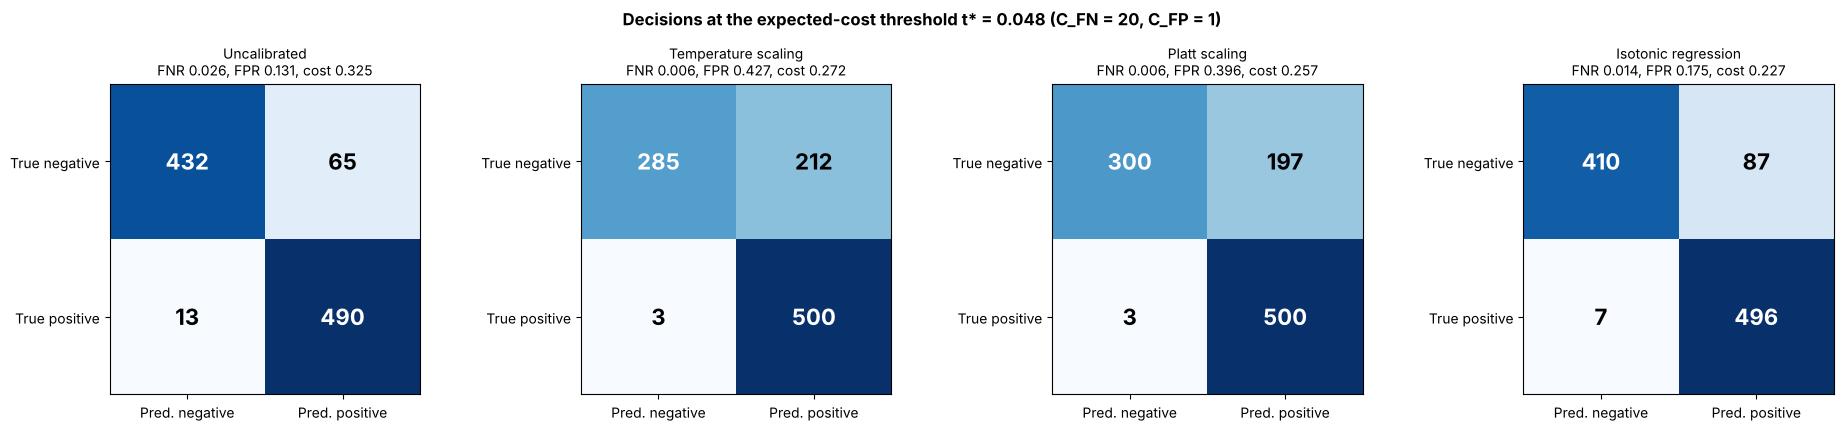

method                    FNR    FPR  mean cost
Uncalibrated            0.026  0.131     0.3250
Temperature scaling     0.006  0.427     0.2720
Platt scaling           0.006  0.396     0.2570
Isotonic regression     0.014  0.175     0.2270

Lowest cost at t*: Isotonic regression (0.2270); oracle threshold on test data: 0.2120.
With miscalibrated probabilities, the theoretically optimal threshold t* is applied to the wrong scale.


In [10]:
C_FN, C_FP = 20.0, 1.0
t_star = C_FP / (C_FP + C_FN)

def confusion(p_pos, y, thr):
    d = p_pos > thr
    tp = np.sum(d & (y == 1)); fp = np.sum(d & (y == 0)); fn = np.sum(~d & (y == 1)); tn = np.sum(~d & (y == 0))
    return tp, fp, fn, tn

fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
rows = []
for ax, (m, P) in zip(axes, methods.items()):
    tp, fp, fn, tn = confusion(P[:, 1], y_test, t_star)
    cost = (C_FN * fn + C_FP * fp) / len(y_test)
    rows.append((m, fn / (tp + fn), fp / (fp + tn), cost))
    cm = np.array([[tn, fp], [fn, tp]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16, fontweight="bold",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred. negative", "Pred. positive"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["True negative", "True positive"])
    ax.grid(False)
    ax.set_title(f"{m}\nFNR {fn / (tp + fn):.3f}, FPR {fp / (fp + tn):.3f}, cost {cost:.3f}", fontsize=10)
plt.suptitle(f"Decisions at the expected-cost threshold t* = {t_star:.3f} (C_FN = {C_FN:g}, C_FP = {C_FP:g})", fontweight="bold")
plt.tight_layout(); plt.show()

# Best achievable cost with the threshold tuned on the TEST set (oracle, for reference only)
oracle = min((C_FN * confusion(probs_raw[:, 1], y_test, th)[2] + C_FP * confusion(probs_raw[:, 1], y_test, th)[1]) / len(y_test)
             for th in np.unique(probs_raw[:, 1]))
print(f"{'method':22s} {'FNR':>6s} {'FPR':>6s} {'mean cost':>10s}")
for m, fnr, fpr, cost in rows:
    print(f"{m:22s} {fnr:6.3f} {fpr:6.3f} {cost:10.4f}")
best = min(rows, key=lambda r: r[3])
print(f"\nLowest cost at t*: {best[0]} ({best[3]:.4f}); oracle threshold on test data: {oracle:.4f}.")
print("With miscalibrated probabilities, the theoretically optimal threshold t* is applied to the wrong scale.")

### 5.2 Calibration under distribution shift

Calibration is measured on a particular distribution. Below, the test inputs are perturbed with increasing Gaussian noise, a stand-in for sensor degradation (rain, dirt). The temperature fitted on clean validation data is kept fixed.

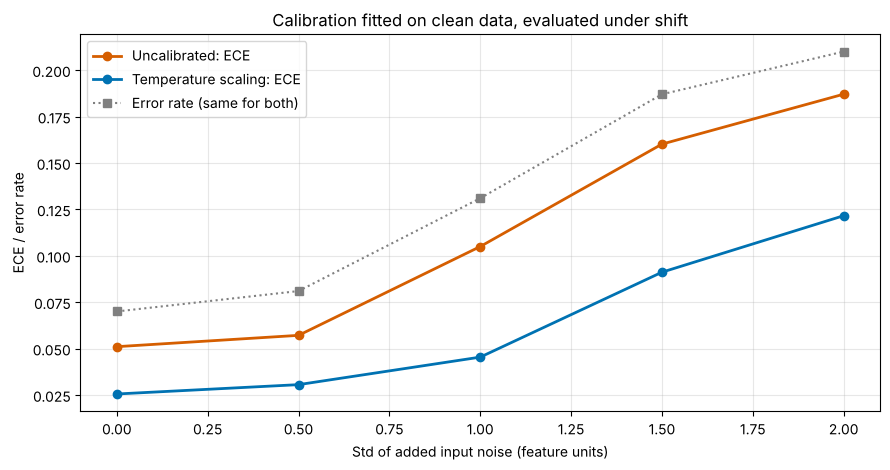

 noise std              method  accuracy  mean confidence   ECE
       0.0        Uncalibrated     0.930            0.980 0.051
       0.0 Temperature scaling     0.930            0.914 0.026
       0.5        Uncalibrated     0.919            0.973 0.057
       0.5 Temperature scaling     0.919            0.905 0.031
       1.0        Uncalibrated     0.869            0.968 0.105
       1.0 Temperature scaling     0.869            0.901 0.045
       1.5        Uncalibrated     0.813            0.969 0.160
       1.5 Temperature scaling     0.813            0.898 0.091
       2.0        Uncalibrated     0.790            0.971 0.187
       2.0 Temperature scaling     0.790            0.905 0.122

With T fixed, ECE grows from 0.026 (no shift) to 0.122 at noise std 2.0; mean confidence 0.905 vs accuracy 0.790.


In [11]:
shift_levels = [0.0, 0.5, 1.0, 1.5, 2.0]
shift_rows = []
for s in shift_levels:
    X_s = X_test + s * rng.standard_normal(X_test.shape)
    with torch.no_grad():
        z_s = model(tt(X_s)).double().numpy()
    for name, T in [("Uncalibrated", 1.0), ("Temperature scaling", T_opt)]:
        P = softmax(logits2(z_s), T)
        shift_rows.append((s, name, np.mean(P.argmax(1) == y_test), P.max(1).mean(), expected_calibration_error(P, y_test)))
shift = pd.DataFrame(shift_rows, columns=["noise std", "method", "accuracy", "mean confidence", "ECE"])

fig, ax = plt.subplots(figsize=(9, 4.8))
for name, c in [("Uncalibrated", OI[5]), ("Temperature scaling", OI[4])]:
    d = shift[shift.method == name]
    ax.plot(d["noise std"], d["ECE"], "o-", color=c, lw=2, label=f"{name}: ECE")
d = shift[shift.method == "Temperature scaling"]
ax.plot(d["noise std"], 1 - d["accuracy"], "s:", color="grey", label="Error rate (same for both)")
ax.set_xlabel("Std of added input noise (feature units)"); ax.set_ylabel("ECE / error rate")
ax.set_title("Calibration fitted on clean data, evaluated under shift"); ax.legend()
plt.tight_layout(); plt.show()
print(shift.round(3).to_string(index=False))
ts = shift[shift.method == "Temperature scaling"].set_index("noise std")
print(f"\nWith T fixed, ECE grows from {ts.loc[0.0, 'ECE']:.3f} (no shift) to {ts.loc[shift_levels[-1], 'ECE']:.3f} "
      f"at noise std {shift_levels[-1]}; mean confidence {ts.loc[shift_levels[-1], 'mean confidence']:.3f} vs accuracy "
      f"{ts.loc[shift_levels[-1], 'accuracy']:.3f}.")

Calibration is a property of a model *and a distribution*. For a safety argument this means: report calibration per ODD slice (day/night, weather, sensor condition), monitor it in the field with labelled audits, and do not assume that a calibrator fitted on clean development data transfers to degraded conditions (Ovadia et al., 2019).

## Key takeaways

- Calibration compares **top-label confidence with observed accuracy**; reliability diagrams must be labelled and coloured accordingly.
- Report **ECE together with NLL and Brier**, each with a **bootstrap CI**; small ECE differences are often within the noise.
- **Temperature scaling**: one parameter, fitted by minimising validation NLL over $\log T$ in float64. $T>1$ means the model was overconfident.
- TS preserves the argmax decision; Platt (bias term) and isotonic regression can change accuracy and ranking; any calibrator changes decisions at thresholds other than 0.5.
- Fit calibrators on a validation set; report on a separate test set **and on shifted data**.
- Calibration is required for expected-cost decisions; FNR-targeted thresholds are set on validation data (or with conformal risk control) and do not need it.

## Self-assessment

1. What does a reliability-diagram bin *below* the diagonal mean?
2. Why is temperature scaling fitted with NLL rather than ECE?
3. Why did a float32 loss with finite-difference gradients leave $T$ at 1?
4. Which of TS, Platt and isotonic regression can change test accuracy, and why?
5. You need FNR ≤ 1 % for pedestrians. Do you need calibration to choose the threshold?
6. Why can a model calibrated on validation data be badly calibrated in fog?

<details>
<summary>Answers</summary>

1. The mean confidence in that bin exceeds the accuracy: the model is overconfident there.
2. NLL is a smooth, proper scoring rule whose minimiser is the calibrated predictive distribution within the family; ECE is binned, non-differentiable, biased and depends on the binning.
3. Scaling the logits by $1/(1+10^{-8})$ does not change a float32 loss value, so the numerical gradient is exactly zero and the optimiser stops immediately at its starting point.
4. Platt (the bias $b$ moves the 0.5 boundary) and isotonic regression (piecewise-constant map creates ties and can move scores across 0.5). TS divides logits by a positive constant, which preserves their sign and order.
5. No. Any monotone score can be thresholded at the value that achieves FNR ≤ 1 % on validation data (with a statistical margin, e.g. conformal risk control). Calibration matters if the probability itself is used, e.g. in fusion or expected-cost decisions.
6. Calibration holds for the distribution it was measured on. Under shift, accuracy falls but confidence often does not fall as much, so the model becomes overconfident.
</details>

## References

- Guo, C., Pleiss, G., Sun, Y., Weinberger, K. Q. (2017). On calibration of modern neural networks. ICML 2017. arXiv:1706.04599
- Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. In *Advances in Large Margin Classifiers*, MIT Press.
- Zadrozny, B., Elkan, C. (2002). Transforming classifier scores into accurate multiclass probability estimates. KDD 2002. https://doi.org/10.1145/775047.775151
- Niculescu-Mizil, A., Caruana, R. (2005). Predicting good probabilities with supervised learning. ICML 2005. https://doi.org/10.1145/1102351.1102430
- Nixon, J. et al. (2019). Measuring calibration in deep learning. CVPR Workshops 2019. arXiv:1904.01685
- Kumar, A., Liang, P., Ma, T. (2019). Verified uncertainty calibration. NeurIPS 2019. arXiv:1909.10155
- Ovadia, Y. et al. (2019). Can you trust your model's uncertainty? Evaluating predictive uncertainty under dataset shift. NeurIPS 2019. arXiv:1906.02530
- Küppers, F. et al. (2020). Multivariate confidence calibration for object detection. CVPR Workshops 2020. arXiv:2004.13546
- ISO/PAS 8800:2024; ISO 21448:2022.

---
**Navigation:** ← [03 MC dropout and deep ensembles](03_mc_dropout_and_deep_ensembles.ipynb) · [Module index](README.md) · [05 Conformal prediction](05_conformal_prediction.ipynb) →

### Further practice

**Try this:** change the number of bins (5, 10, 25) and watch the ECE estimate move; train for 20 instead of 60 epochs and compare the fitted temperature; extend the decision analysis to a three-class problem with `softmax(logits, T)`.

The author's companion repository [AI-Perception-Safety-Workshop](https://github.com/milinpatel07/AI-Perception-Safety-Workshop) has further exercises.